In [1]:
# Вариант 5

def qZ(x, y):
    return (x - 3 * y + 1) / (3 * x ** 2 + y ** 2 + 1)

In [2]:
def qSumZ(Z):
    return sum(Z)

In [3]:
def exchangeScheme(oldX, oldY, sortedId):
    X = [0 for i in range(4)]
    Y = [0 for i in range(4)]

    X[2] = oldX[sortedId[2]]
    X[3] = oldX[sortedId[2]]

    X[0] = oldX[sortedId[0]]

    X[1] = oldX[sortedId[1]]

    Y[0] = oldY[sortedId[2]]
    Y[1] = oldY[sortedId[2]]

    Y[2] = oldY[sortedId[0]]

    Y[3] = oldY[sortedId[1]]

    return X, Y

In [4]:
def sorting(Z):
    sortedId = sorted(range(len(Z)), key = lambda k: Z[k])

    return sortedId

In [5]:
def evoStep(X, Y, Z):
    _, minId = min((value, id) for (id, value) in enumerate(Z))
    X = X[:]
    Y = Y[:]
    Z = Z[:]

    X.pop(minId)
    Y.pop(minId)
    Z.pop(minId)

    return X, Y, Z

In [6]:
def evoSteps(X, Y, stepsNum = 4):
    results = []

    for i in range(4):
        arrZ = [qZ(x, Y[i]) for i, x in enumerate(X)]

        X, Y, Z = evoStep(X, Y, arrZ)

        X, Y = exchangeScheme(X, Y, sorting(Z))

        results.append([X, Y, qSumZ(arrZ), arrZ])

    return X, Y, results

In [7]:
X = [-2, -1, 0, 2]
Y = [-2, 0, -1, 1]

results = evoSteps(X, Y)

In [8]:
for i in range(len(results[2])):
    print(f"max_{i + 1}_step: {results[2][i][2]}")

qualityArrZ = []

for i in range(len(results[2])):
    qualityArrZ += results[2][i][3]

print(f"max Z: {max(qualityArrZ)}")

max_1_step: 2.2941176470588234
max_2_step: 0.9714285714285713
max_3_step: 4.823529411764706
max_4_step: 5.828571428571428
max Z: 2.0


In [9]:
# Вариант 4

import networkx as nx
from math import e

In [27]:
distances = [(1, 2, 23),
           (1, 3, 42),
           (1, 4, 40),
           (1, 5, 25),
           (1, 6, 22),
           (2, 3, 20),
           (2, 4, 30),
           (2, 5, 34),
           (2, 6, 13),
           (3, 4, 22),
           (3, 5, 41),
           (3, 6, 21),
           (4, 5, 26),
           (4, 6, 19),
           (5, 6, 22)]

V = [1, 3, 4, 5, 6, 3, 1]

Z = [(4, 5),
    (5, 6),
    (2, 4),
    (6, 2)]

P = [78, 24, 63, 17]

T = 100

In [28]:
def probability(delta, T):
    return 100 * e ** (-delta / T)

def reductTemp(prevT):
    nextT = 0.5 * prevT

    return nextT

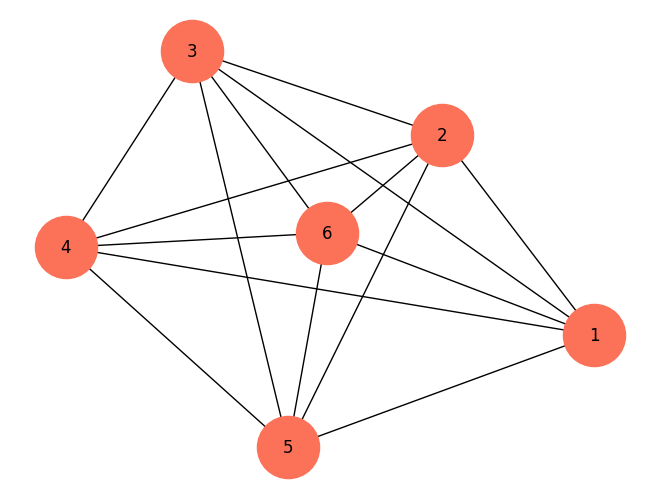

In [29]:
graph = nx.Graph()
graph.add_weighted_edges_from(distances)

nx.draw_kamada_kawai(graph, node_color = "#fb7258", node_size = 2000, with_labels = True)

In [30]:
def edgeLength(i, j, distances, roundTrip = True):
    if roundTrip:
        return max([(item[2] if (item[0] == i and item[1] == j) or (item[1] == i and item[0] == j) else -1) for item in distances])
    else:
        return max([(item[2] if (item[0] == i and item[1] == j) else -1) for item in distances])

In [31]:
def routeLength(V, distances):
    edges = []

    for i in range(len(V) - 1):
        edges.append(edgeLength(V[i], V[i + 1], distances))

    return sum(edges)

In [32]:
def routeOneReplacement(arrV, Z, replacementByName = True):
    decrement = 1 if replacementByName else 0

    arrV[Z[0] - decrement], arrV[Z[1] - decrement] = arrV[Z[1] - decrement], arrV[Z[0] - decrement]

    return arrV

In [33]:
def routeReplacement(V, Z):
    for z in Z:
        V = routeOneReplacement(V, z)

    return V

In [34]:
def chooseRoute(distances, V, Z, T, P):
    sumLength = routeLength(V, distances)
    arrSum = [sumLength]

    for i in range(len(Z)):
        newV = routeOneReplacement(V[:], Z[i])
        newS = routeLength(newV, distances)
        arrSum.append(newS)
        deltaS = newS - sumLength

        if deltaS > 0:
            p = probability(deltaS, T)

            if p > P[i]:
                V = newV
                sumLength = newS
        else:
            V = newV
            sumLength = newS

        T = reductTemp(T)

    return V, arrSum

In [35]:
def drawRouteGraph(distances, bestRoute):
    newDistances = []

    for i in range(len(bestRoute) - 1):
        for distance in distances:
            if distance[0] == bestRoute[i] and distance[1] == bestRoute[i + 1] or distance[1] == bestRoute[i] and distance[0] == bestRoute[i + 1]:
                newDistances.append(distance)

    graph = nx.Graph()

    graph.add_weighted_edges_from(newDistances)

    nx.draw_kamada_kawai(graph, node_color = "#fb7258", node_size = 2000, with_labels = True)

Лучший выбранный маршрут: [1, 5, 4, 3, 3, 6, 1]
Длина лучшего выбранного маршрута: 115
Длины всех рассмотренных маршрутов: [175, 188, 170, 128, 115]


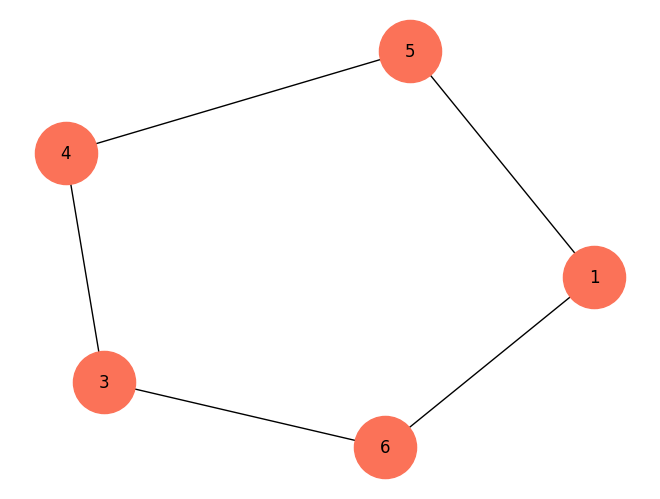

In [36]:
bestRoute, arrLength = chooseRoute(distances, V, Z, T, P)

print(f"Лучший выбранный маршрут: {bestRoute}")
print(f"Длина лучшего выбранного маршрута: {routeLength(bestRoute, distances)}")
print(f"Длины всех рассмотренных маршрутов: {arrLength}")

drawRouteGraph(distances, bestRoute)